--- Step 1: Creating WCW Retro T-Shirt Dataset ---
Dataset generated successfully with 20 T-shirt items.

--- Step 2: Running NLP Vectorization ---
Vocabulary shape (Items, Unique NLP Tokens): (20, 100)

--- Step 3: Training K-Means Model ---
Clustering complete! Items assigned to groups.

--- Step 4: Extracting Top NLP Words per Cluster ---
Cluster 0 Top Keywords: ['featuring', 'logo', 'black']
Cluster 1 Top Keywords: ['celebrating', 'wrestling', 'tee']
Cluster 2 Top Keywords: ['vintage', 'shirt', 'style']
Cluster 3 Top Keywords: ['graphic', 'tee', 'showing']

--- Sample Allocation Table ---
                        product_name  cluster
        nWo Hollywood Black Logo Tee        0
            Wolfpac Red Logo T-Shirt        0
           Sting Icon Scorpion Shirt        3
             Goldberg Who's Next Tee        3
     Hollywood Hogan Lightning Shirt        0
Diamond Dallas Page DDP Bang T-Shirt        3
              nWo 4 Life Vintage Tee        2
        Sting Face Paint Retro S

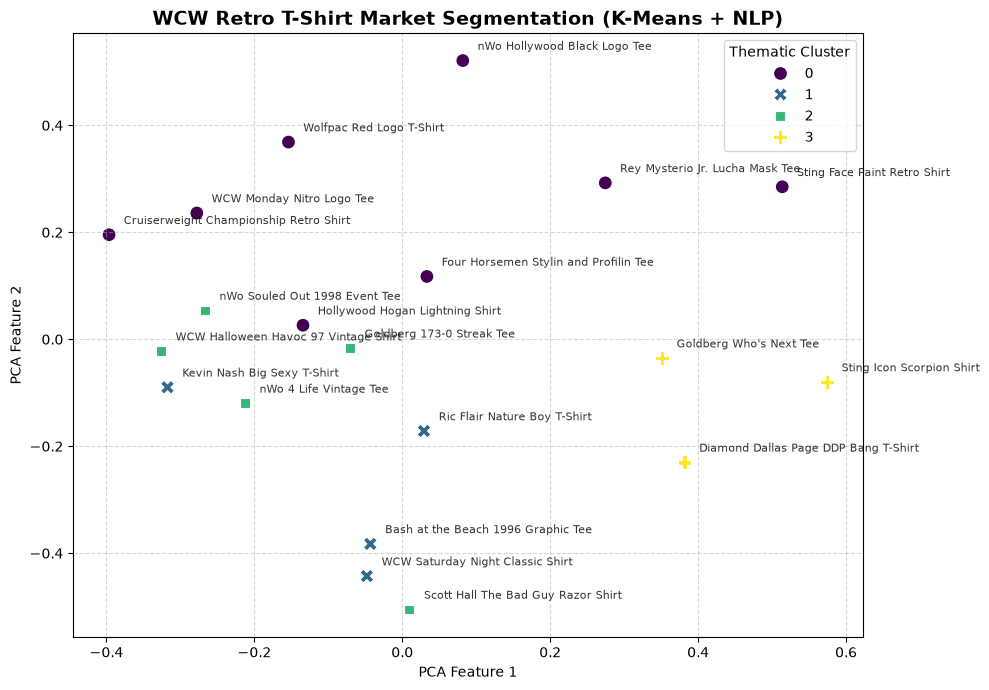

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# ---------------------------------------------------------
# 1. CREATE SYNTHETIC WCW RETRO T-SHIRT DATASET
# ---------------------------------------------------------
print("--- Step 1: Creating WCW Retro T-Shirt Dataset ---")

data = {
    "product_name": [
        "nWo Hollywood Black Logo Tee", "Wolfpac Red Logo T-Shirt", 
        "Sting Icon Scorpion Shirt", "Goldberg Who's Next Tee",
        "Hollywood Hogan Lightning Shirt", "Diamond Dallas Page DDP Bang T-Shirt",
        "nWo 4 Life Vintage Tee", "Sting Face Paint Retro Shirt",
        "Goldberg 173-0 Streak Tee", "Kevin Nash Big Sexy T-Shirt",
        "Scott Hall The Bad Guy Razor Shirt", "Rey Mysterio Jr. Lucha Mask Tee",
        "Cruiserweight Championship Retro Shirt", "WCW Monday Nitro Logo Tee",
        "WCW Saturday Night Classic Shirt", "Four Horsemen Stylin and Profilin Tee",
        "Ric Flair Nature Boy T-Shirt", "nWo Souled Out 1998 Event Tee",
        "WCW Halloween Havoc 97 Vintage Shirt", "Bash at the Beach 1996 Graphic Tee"
    ],
    "description": [
        "Classic black t-shirt featuring the iconic white nWo New World Order Hollywood logo.",
        "Red and black logo shirt for the nWo Wolfpac faction featuring Kevin Nash and Lex Luger.",
        "Dark teal tee showing Sting the Icon with his signature white scorpion graphic.",
        "Heavy graphic tee featuring Bill Goldberg with his legendary catchphrase Who's Next.",
        "Features Hollywood Hulk Hogan surrounded by airbrushed lightning bolts and nWo branding.",
        "Black graphic tee showing DDP throwing up the diamond cutter hand sign with a Bang text.",
        "Vintage distressed style shirt with the classic nWo 4 Life text across the chest.",
        "White tee featuring a minimalist print of Sting's iconic black and white crow face paint.",
        "Commemorative streak shirt highlighting Goldberg's historic undefeated 173-0 record.",
        "Retro wrestling shirt celebrating Big Sexy Kevin Nash with an airbrushed portrait.",
        "Vintage style tee dedicated to Scott Hall, the Bad Guy, with neon graffiti text.",
        "Colorful graphic shirt featuring Rey Mysterio Jr. wearing his iconic purple lucha libre mask.",
        "Classic retro shirt highlighting the WCW cruiserweight champion title belt logo.",
        "Official retro merchandise featuring the metallic burning WCW Monday Nitro TV show logo.",
        "Throwback tee dedicated to the old school WCW Saturday Night wrestling television program.",
        "Vintage black shirt honoring the legendary Four Horsemen stable featuring Ric Flair.",
        "Stylin and profilin luxury tee celebrating the 16-time world champion Nature Boy Ric Flair.",
        "Event merchandise shirt from the infamous nWo Souled Out 1998 pay-per-view.",
        "Spooky vintage retro shirt from the legendary WCW Halloween Havoc 1997 event.",
        "Historical wrestling tee celebrating the formation of the nWo at Bash at the Beach 1996."
    ],
    "price": [29.99, 29.99, 32.50, 28.00, 34.99, 27.50, 31.00, 30.00, 33.00, 29.99,
              29.99, 28.50, 35.00, 26.00, 26.00, 32.00, 35.00, 39.99, 39.99, 45.00]
}

df = pd.DataFrame(data)
print(f"Dataset generated successfully with {len(df)} T-shirt items.\n")

# ---------------------------------------------------------
# 2. NLP PREPROCESSING & VECTORIZATION (TF-IDF)
# ---------------------------------------------------------
print("--- Step 2: Running NLP Vectorization ---")

# We use standard English stop words to filter out common filler words (the, a, and, with)
# We also include 'shirt', 'shirt', 'tee' if needed, but TF-IDF automatically lowers their weight if they appear everywhere.
vectorizer = TfidfVectorizer(stop_words='english', lowercase=True, max_features=100)
tfidf_matrix = vectorizer.fit_transform(df['description'])

print(f"Vocabulary shape (Items, Unique NLP Tokens): {tfidf_matrix.shape}\n")

# ---------------------------------------------------------
# 3. K-MEANS CLUSTERING
# ---------------------------------------------------------
print("--- Step 3: Training K-Means Model ---")

# Let's group the T-shirts into 4 distinct thematic buckets
NUM_CLUSTERS = 4
kmeans = KMeans(n_clusters=NUM_CLUSTERS, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(tfidf_matrix)

# Print out the results of the clustering
print("Clustering complete! Items assigned to groups.\n")

# ---------------------------------------------------------
# 4. EVALUATING CLUSTER THEMES (Top Keywords)
# ---------------------------------------------------------
print("--- Step 4: Extracting Top NLP Words per Cluster ---")
order_centroids = kmeans.cluster_centers_.argsort()[:, ::-1]
terms = vectorizer.get_feature_names_out()

cluster_themes = {}
for i in range(NUM_CLUSTERS):
    top_words = [terms[ind] for ind in order_centroids[i, :3]]
    cluster_themes[i] = ", ".join(top_words)
    print(f"Cluster {i} Top Keywords: {top_words}")

# Map cluster IDs back to a descriptive table display
print("\n--- Sample Allocation Table ---")
print(df[['product_name', 'cluster']].head(10).to_string(index=False))
print("\n")

# ---------------------------------------------------------
# 5. VISUALIZING THE CLUSTERS (Using PCA)
# ---------------------------------------------------------
print("--- Step 5: Plotting the Merch Clusters ---")

# Reduce the high-dimensional NLP space down to 2 dimensions so we can plot it
pca = PCA(n_components=2, random_state=42)
pca_features = pca.fit_transform(tfidf_matrix.toarray())
df['pca_x'] = pca_features[:, 0]
df['pca_y'] = pca_features[:, 1]

plt.figure(figsize=(10, 7))
sns.scatterplot(
    x='pca_x', y='pca_y', 
    hue='cluster', 
    palette='viridis', 
    data=df, 
    s=100, 
    style='cluster'
)

# Label points with product names for clear scannability
for i in range(len(df)):
    plt.text(
        df['pca_x'][i] + 0.02, 
        df['pca_y'][i] + 0.02, 
        df['product_name'][i], 
        fontsize=8, 
        alpha=0.8
    )

plt.title('WCW Retro T-Shirt Market Segmentation (K-Means + NLP)', fontsize=14, fontweight='bold')
plt.xlabel('PCA Feature 1')
plt.ylabel('PCA Feature 2')
plt.legend(title='Thematic Cluster')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()
